# 07 - Classification de bout en bout (et modele de projet pour tes donnees)

NEU-CLS (6 defauts de bande d'acier laminee a chaud) traite comme un vrai projet :

1. catalogue et decoupage (les memes que la recette) ;
2. **choix du pretraitement a la metrique** : une sonde lineaire sur un backbone gele compare
   plusieurs chaines OpenCV, sur des images propres et sous un eclairage degrade ;
3. entrainement d'un resnet18 pre-entraine (strategie partial) et d'un reseau ecrit de zero ;
4. evaluation complete : rapport par classe, matrice de confusion, ROC / PR, calibration,
   erreurs les plus sures, Grad-CAM ecrit a la main ;
5. **seuil de rejet** choisi sur la validation (les images douteuses vont a un operateur) ;
6. export ONNX verifie + carte du modele, prediction sans PyTorch, controle avec le predicteur
   de production.

- Donnees : `python tools/get_data/get_neu_cls.py`. Pour tes images : section "Adapter a tes
  donnees" en fin de notebook (seule la cellule REGLAGES change).
- Duree en mode QUICK sur un CPU 2 coeurs : 5 a 7 minutes.

**Le fil** (memes etapes que le cours et que `ETAPES.md`, a la racine de la toolbox) :

```
1 Imports et reglages -> 3 Cataloguer -> 4 Decouper -> 5 Pretraiter (choisi a la metrique)
  -> 6 Augmenter -> 7 Charger par lots -> 8 Modele -> 9 Perte et optimiseur -> 10 Entrainer
  (deux fois : resnet18 pre-entraine, puis reseau ecrit de zero)
  -> 11 Evaluer (test, Grad-CAM, seuil de rejet) -> 12 Sauvegarder et exporter -> 13 Predire
```

L'etape 2 (importer et explorer) n'est pas refaite ici : notebooks 00, 01 et 05.

## Etape 1 - Imports et reglages

In [1]:
import json  # json : lire et ecrire des fichiers texte structures (ici la carte du modele)
import math  # math : fonctions mathematiques de base (pi, cosinus, sinus)
import platform  # platform : donne la version de Python, notee dans la carte du modele
import time  # time : chronometre (duree d'entrainement, latence)
from datetime import UTC, datetime  # datetime : date et heure ; UTC : heure universelle (date de creation du modele)
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture, ecriture et traitement d'images
import matplotlib.pyplot as plt  # matplotlib : dessiner des graphiques et afficher des images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import onnxruntime as ort  # onnxruntime : execute un modele ONNX (format standard d'echange de reseaux) sans PyTorch
import pandas as pd  # pandas : tableaux de donnees (DataFrame) a colonnes nommees, comme une feuille de tableur
import torch  # PyTorch : tenseurs (tableaux de nombres, sur CPU ou carte graphique) et reseaux de neurones
import torch.nn as nn  # nn : briques des reseaux (couches, fonctions de perte = mesure de l'erreur a diminuer)
import torch.nn.functional as F  # F : operations sans poids a apprendre (relu, interpolation...)
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from sklearn.linear_model import LogisticRegression  # regression logistique : classifieur lineaire simple et rapide
from sklearn.metrics import balanced_accuracy_score, f1_score, log_loss  # metriques de classification (expliquees a l'etape 11)
from sklearn.model_selection import train_test_split  # coupe une liste en deux parts tirees au hasard (ex. train / test)
from sklearn.preprocessing import StandardScaler  # centre-reduit chaque colonne : moyenne 0, ecart-type 1
from torch.utils.data import DataLoader, Dataset  # Dataset : donne une image par numero ; DataLoader : les regroupe en lots
from torchvision import models  # modeles de vision connus (resnet18...) avec leurs poids pre-entraines
from torchvision.transforms import v2  # transformations d'images pour l'augmentation (retournements...)

from vtb import viz  # viz : affichages de la toolbox (grilles d'images, courbes, matrices de confusion)

QUICK = True  # True : essai rapide (moins d'epoques et d'images) ; False : reglages complets de la recette
DATA_DIR = Path("data/raw/neu_cls_flat")  # un sous-dossier par classe (le nom du sous-dossier = le nom de la classe)
EXTENSIONS = {".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff"}  # extensions de fichier reconnues comme images
READ_COLOR = "rgb"  # rgb : le gris est recopie sur 3 canaux (les poids ImageNet attendent 3 canaux)
IMAGE_SIZE = 128  # cote, en pixels, des images donnees au reseau (apres redimensionnement)
VAL_FRACTION, TEST_FRACTION = 0.15, 0.15  # 15 % des images pour la validation, 15 % pour le test, le reste pour l'entrainement
# epoque = un passage complet sur toutes les images d'entrainement
EPOCHS = 4 if QUICK else 10  # resnet18 partial (recette : resnet18_partial.yaml)
SCRATCH_EPOCHS = 4 if QUICK else 15  # reseau de zero (recette : simple_cnn.yaml)
PROBE_PER_CLASS = 60 if QUICK else 200  # images par classe pour comparer les pretraitements
# BATCH_SIZE : 32 images traitees ensemble a chaque pas (un lot, ou batch) : plus grand = plus rapide mais plus de memoire ;
# LR : taux d'apprentissage, la taille des pas de correction des poids ; PATIENCE : arret apres 4 epoques sans progres
BATCH_SIZE, LR, PATIENCE = 32, 1e-3, 4
TARGET_ACCEPTED_ACCURACY = 0.995  # seuil de rejet : exactitude visee sur les images acceptees
SEED = 42  # graine du hasard : memes tirages a chaque execution, donc resultats reproductibles
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # carte graphique (cuda) si presente, sinon processeur
OUT = Path("outputs/notebooks/07_classification")  # dossier ou le notebook ecrit ses resultats
EXPORT = OUT / "export"  # sous-dossier du modele exporte (model.onnx + carte du modele)
EXPORT.mkdir(parents=True, exist_ok=True)  # cree les dossiers s'ils manquent (sans erreur s'ils existent deja)
viz.setup_notebook(dpi=80, fmt="jpeg")  # figures en JPEG a 80 points par pouce : notebook plus leger
torch.manual_seed(SEED)  # fixe le hasard de PyTorch (poids initiaux, melange des lots)
np.random.seed(SEED)  # fixe le hasard de numpy

## Etapes 3 et 4 - Cataloguer et decouper

Stratifie, graine 42 : le meme `split.csv` que la recette (detail et autres strategies :
notebook 01).

In [2]:
rows = [  # liste de dictionnaires : un par image, avec son chemin et sa classe
    {"path": str(p), "label": d.name}  # chemin du fichier et classe (= nom du sous-dossier)
    for d in sorted(x for x in DATA_DIR.iterdir() if x.is_dir())  # pour chaque sous-dossier (une classe), par ordre alphabetique
    # pour chaque fichier du dossier (sous-dossiers compris) dont l'extension est celle d'une image
    for p in sorted(q for q in d.rglob("*") if q.is_file() and q.suffix.lower() in EXTENSIONS)
]
catalog = pd.DataFrame(rows)  # catalogue : un tableau (DataFrame) avec une ligne par image, colonnes path et label
class_names = sorted(catalog["label"].unique())  # noms des classes tries : la position dans cette liste = numero de la classe
catalog["split"] = "train"  # par defaut chaque image va a l'entrainement ; on en retire ensuite le test et la validation
# test (images gardees de cote pour la mesure finale) : 15 % tires au hasard ;
# stratify : chaque classe garde la meme proportion que dans le jeu complet
_, test_idx = train_test_split(catalog.index, test_size=TEST_FRACTION, stratify=catalog["label"], random_state=SEED)
catalog.loc[test_idx, "split"] = "test"  # marque ces images comme images de test
rest = catalog[catalog["split"] == "train"]  # images restantes, parmi lesquelles on tire la validation
# validation (images pour regler et choisir) : 0.15 / 0.85 du reste = 15 % du total, stratifiee elle aussi
_, val_idx = train_test_split(rest.index, test_size=VAL_FRACTION / (1 - TEST_FRACTION), stratify=rest["label"], random_state=SEED)
catalog.loc[val_idx, "split"] = "val"  # marque ces images comme images de validation
catalog.to_csv(OUT / "split.csv", index=False)  # ecrit le decoupage sur disque (relu et compare a la recette en fin de notebook)
# un tableau par sous-ensemble ; reset_index : lignes renumerotees 0, 1, 2... (numero de ligne = position)
frames = {s: catalog[catalog["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}
print(pd.crosstab(catalog["label"], catalog["split"], margins=True))  # nombre d'images par classe et par sous-ensemble, avec totaux

split      test  train  val   All
label                            
crazing      45    210   45   300
inclusion    45    210   45   300
patches      45    210   45   300
pitted       45    210   45   300
rolled       45    210   45   300
scratches    45    210   45   300
All         270   1260  270  1800


## Etape 5 - Pretraiter : les operations de pretraitement candidates

Ecrites a l'identique de celles de la toolbox (memes noms, memes parametres) : la carte du
modele pourra les citer et le predicteur de production les rejouer. Toutes rendent le type
d'entree (uint8 / uint16) ; les calculs se font en flottant dans [0, 1].

- `shading_division` : divise par le fond flou (eclairage multiplicatif, vignettage) ; sigma
  nettement plus grand que les defauts, sinon la division les efface ;
- `clahe` : contraste local par tuiles, amplification bornee ;
- `percentile_stretch` : etire [p1, p99] sur toute la dynamique (robuste aux pixels aberrants) ;
- `resize` : interpolation area pour reduire (pas de moirage sur la texture du metal).

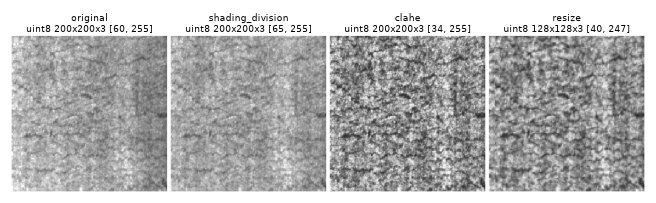

In [3]:
def read_image(path, color=READ_COLOR):  # lit un fichier ; renvoie un tableau (H, W) en gris ou (H, W, 3) en RGB
    # lit les octets avec numpy puis decode avec OpenCV : marche avec les chemins accentues ; UNCHANGED garde 8 ou 16 bits
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible : {path}")  # on arrete tout de suite avec un message clair
    if image.ndim == 3 and image.shape[2] == 4:  # image a 4 canaux : couleur + transparence (alpha)
        image = image[:, :, :3]  # on garde les 3 canaux de couleur, on jette la transparence
    if color == "gray":  # si on demande du gris
        return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image  # couleur -> gris ; deja grise : inchangee
    # sinon RGB : une image grise est recopiee sur 3 canaux ; une image couleur passe de BGR (ordre d'OpenCV) a RGB
    return np.stack([image] * 3, axis=-1) if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def peak_of(image):  # valeur maximale possible d'un pixel selon le type de l'image
    return 65535.0 if image.dtype == np.uint16 else 255.0  # 16 bits : 65535 ; 8 bits : 255 (sert a ramener les pixels dans [0, 1])


def from_float(values, like):  # ramene des flottants [0, 1] au type entier de l'image `like` (uint8 ou uint16)
    return (np.clip(values, 0.0, 1.0) * peak_of(like) + 0.5).astype(like.dtype)  # borne a [0, 1], remet a l'echelle, +0.5 = arrondi


def per_channel(func, image):  # applique func a chaque canal separement ; renvoie l'image recomposee
    # image grise : un seul appel ; couleur : un appel par canal, puis les canaux sont empiles a nouveau
    return func(image) if image.ndim == 2 else np.stack([func(image[:, :, c]) for c in range(image.shape[2])], axis=-1)


def resize(image, size=256, interpolation="auto"):  # redimensionne a size x size (ou (hauteur, largeur)) ; renvoie la nouvelle image
    height, width = (size, size) if isinstance(size, int) else (int(size[0]), int(size[1]))  # un entier = image carree
    # nom de la methode d'interpolation (calcul des nouveaux pixels) -> constante OpenCV
    flags = {"nearest": cv2.INTER_NEAREST, "linear": cv2.INTER_LINEAR, "cubic": cv2.INTER_CUBIC, "area": cv2.INTER_AREA}
    if interpolation == "auto":  # choix automatique de la methode
        # reduction : area (moyenne des pixels, pas de moirage) ; agrandissement : lineaire
        flag = cv2.INTER_AREA if height * width < image.shape[0] * image.shape[1] else cv2.INTER_LINEAR
    else:  # methode imposee par son nom
        flag = flags[interpolation]  # traduit le nom en constante OpenCV
    return cv2.resize(image, (width, height), interpolation=flag)  # attention : OpenCV attend (largeur, hauteur)


def estimate_background(channel, sigma, downscale=4):  # estime le fond lisse (l'eclairage) d'un canal ; renvoie des float32
    """Flou gaussien tres large, calcule sur l'image reduite (meme resultat pour un fond lisse, 16 fois moins de calcul)."""
    height, width = channel.shape  # dimensions du canal
    factor = max(1, int(downscale))  # facteur de reduction (au moins 1 = pas de reduction)
    small = (  # image reduite pour aller plus vite (ou le canal lui-meme si factor vaut 1)
        # divise largeur et hauteur par factor (au moins 1 pixel), seulement si factor > 1
        cv2.resize(channel, (max(1, width // factor), max(1, height // factor)), interpolation=cv2.INTER_AREA) if factor > 1 else channel
    )
    # flou gaussien (moyenne ponderee des voisins) tres large : il ne reste que les variations lentes, c'est-a-dire le fond ;
    # sigma divise par factor car l'image est plus petite ; (0, 0) : taille du noyau deduite de sigma ; bords en miroir
    blurred = cv2.GaussianBlur(small, (0, 0), sigmaX=max(sigma / factor, 0.5), borderType=cv2.BORDER_REFLECT)
    if factor > 1:  # si l'image avait ete reduite
        blurred = cv2.resize(blurred, (width, height), interpolation=cv2.INTER_LINEAR)  # on remet le fond a la taille d'origine
    return blurred.astype(np.float32)  # le fond, en flottants


# corrige un eclairage inegal en divisant par le fond flou ; renvoie une image du meme type (uint8 / uint16)
def shading_division(image, sigma=50.0, method="gaussian", downscale=4, keep_mean=True):
    if method != "gaussian":  # seule la methode gaussienne est ecrite dans ce notebook
        raise NotImplementedError("le notebook n'ecrit que la methode gaussienne (median : voir vtb)")  # autre methode : erreur explicite

    def correct(channel):  # corrige un seul canal ; renvoie des flottants
        x = channel.astype(np.float32) / peak_of(channel)  # pixels ramenes dans [0, 1]
        background = estimate_background(x, sigma, downscale)  # le fond (eclairage) estime par un flou tres large
        corrected = x / np.maximum(background, 1e-6)  # divise par le fond : l'eclairage s'annule ; 1e-6 evite une division par 0
        return corrected * float(background.mean()) if keep_mean else corrected * 0.5  # remet la luminosite moyenne (sinon autour de 0.5)

    return from_float(per_channel(correct, image), image)  # corrige chaque canal puis revient au type d'origine (uint8 / uint16)


def clahe(image, clip_limit=2.0, tile_grid=8):  # CLAHE : egalise le contraste localement, par tuiles ; renvoie l'image corrigee
    # grille de tile_grid x tile_grid tuiles ; clip_limit borne l'amplification (sinon le bruit explose)
    operator = cv2.createCLAHE(clipLimit=float(clip_limit), tileGridSize=(int(tile_grid), int(tile_grid)))
    if image.ndim == 2:  # image en gris
        return operator.apply(image)  # CLAHE directement sur l'unique canal
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)  # couleur : passage en LAB (L = luminance) ; sur la luminance seulement (uint8)
    lab[:, :, 0] = operator.apply(lab[:, :, 0])  # CLAHE sur le canal L : les couleurs ne bougent pas
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)  # retour en RGB


def percentile_stretch(image, low=1.0, high=99.0):  # etire le contraste entre deux percentiles ; renvoie le type d'entree
    x = image.astype(np.float32) / peak_of(image)  # pixels ramenes dans [0, 1]
    lo, hi = np.percentile(x, [low, high])  # valeurs sous lesquelles tombent 1 % et 99 % des pixels (ignore les pixels aberrants)
    return from_float((x - lo) / max(float(hi - lo), 1e-6), image)  # lo devient 0 et hi devient 1 ; au-dela, rogne


OPS = {"resize": resize, "shading_division": shading_division, "clahe": clahe, "percentile_stretch": percentile_stretch}  # nom -> fonction
DEFAULTS = {  # valeurs par defaut de chaque operation (recopiees dans la carte du modele pour tout rendre explicite)
    "resize": {"size": 256, "interpolation": "auto"},  # defauts de resize
    "shading_division": {"sigma": 50.0, "method": "gaussian", "downscale": 4, "keep_mean": True},  # defauts de shading_division
    "clahe": {"clip_limit": 2.0, "tile_grid": 8},  # defauts de clahe
    "percentile_stretch": {"low": 1.0, "high": 99.0},  # defauts de percentile_stretch
}


def describe(steps):  # complete chaque etape avec ses valeurs par defaut ; renvoie une liste de dictionnaires
    """Chaine complete, valeurs par defaut explicites : ce qui sera recopie dans la carte du modele."""
    # pour chaque etape : son nom, puis les defauts, puis les parametres donnes par l'etape (ils remplacent les defauts)
    return [{"name": s["name"], **DEFAULTS[s["name"]], **{k: v for k, v in s.items() if k != "name"}} for s in steps]


def run_pipeline(image, steps):  # applique une chaine d'operations dans l'ordre ; renvoie l'image transformee
    for step in steps:  # pour chaque etape de la chaine
        # appelle l'operation par son nom, avec ses parametres
        image = OPS[step["name"]](image, **{k: v for k, v in step.items() if k != "name"})
    return image  # l'image apres toutes les etapes


CANDIDATES = {  # chaines de pretraitement candidates ; toutes finissent par un resize a IMAGE_SIZE
    "resize": [{"name": "resize", "size": IMAGE_SIZE}],  # reference : redimensionnement seul
    "shading": [{"name": "shading_division", "sigma": 40.0}, {"name": "resize", "size": IMAGE_SIZE}],  # correction d'eclairage puis resize
    "clahe": [{"name": "clahe", "clip_limit": 2.0}, {"name": "resize", "size": IMAGE_SIZE}],  # contraste local puis resize
    "stretch": [{"name": "percentile_stretch"}, {"name": "resize", "size": IMAGE_SIZE}],  # etirement 1-99 % puis resize
    "shading+clahe": [  # les deux corrections enchainees
        {"name": "shading_division", "sigma": 40.0},  # 1) correction d'eclairage
        {"name": "clahe", "clip_limit": 2.0},  # 2) contraste local
        {"name": "resize", "size": IMAGE_SIZE},  # 3) taille d'entree du reseau
    ],
}
example = read_image(frames["train"]["path"][0])  # premiere image d'entrainement, pour illustrer
# affiche l'image apres chaque etape de la chaine la plus longue ; s=s fige l'etape dans la lambda (sinon toutes verraient la derniere)
viz.pipeline_steps(example, [(s["name"], lambda im, s=s: run_pipeline(im, [s])) for s in CANDIDATES["shading+clahe"]])

## Etape 5 - Pretraiter : choisir le pretraitement a la metrique, pas a l'oeil

Une image "plus belle" n'est pas forcement mieux classee. On mesure : pour chaque chaine, un
resnet18 GELE (ImageNet) transforme les images en vecteurs, une regression logistique apprend
sur un sous-ensemble du train, et on lit le F1 macro sur la validation. Deux validations :
telle quelle, et sous un eclairage degrade (gradient multiplicatif + vignettage, comme une
lampe qui vieillit) : c'est la que la correction d'illumination montre son interet.

Regle de choix : meilleure moyenne des deux F1 de validation ; a egalite (moins d'un point), la
chaine la plus simple.

In [4]:
def degrade_lighting(image, index, strength=0.45):  # simule un mauvais eclairage ; renvoie une image du meme type
    """Eclairage inegal reproductible : rampe d'orientation aleatoire et vignettage."""
    rng = np.random.default_rng(index)  # hasard dont la graine est le numero de l'image : meme degradation a chaque execution
    h, w = image.shape[:2]  # hauteur et largeur
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)  # deux grilles : numero de ligne et numero de colonne de chaque pixel
    angle = rng.uniform(0, 2 * math.pi)  # direction de la rampe de lumiere, tiree au hasard
    # rampe : la lumiere augmente lineairement d'un bord a l'autre dans la direction angle (de -strength a +strength environ)
    ramp = ((xx / w - 0.5) * math.cos(angle) + (yy / h - 0.5) * math.sin(angle)) * strength * 2
    vignette = -strength * 0.6 * (((xx / w - 0.5) ** 2 + (yy / h - 0.5) ** 2) * 2)  # vignettage : plus sombre vers les coins
    # facteur multiplicatif par pixel ; [..., None] ajoute un axe pour multiplier les 3 canaux d'une image couleur
    gain = (1.0 + ramp + vignette)[..., None] if image.ndim == 3 else 1.0 + ramp + vignette
    # applique le gain, borne aux valeurs permises (0 a 255 ou 65535), puis retour au type d'origine
    return np.clip(image.astype(np.float32) * gain, 0, peak_of(image)).astype(image.dtype)


# moyenne et ecart-type des pixels d'ImageNet pour chaque canal (R, G, B) : servent a la normalisation
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def to_tensor(image, mean=IMAGENET_MEAN, std=IMAGENET_STD):  # image numpy (H, W, 3) -> tenseur PyTorch (3, H, W) normalise
    # transpose (H, W, C) -> (C, H, W) : PyTorch veut les canaux d'abord ; / peak_of : pixels dans [0, 1] ; contiguous : memoire d'un bloc
    x = torch.from_numpy(np.ascontiguousarray(image.astype(np.float32).transpose(2, 0, 1) / peak_of(image)))
    # normalisation : retire la moyenne et divise par l'ecart-type de chaque canal, comme lors du pre-entrainement ImageNet
    return (x - torch.tensor(mean).view(-1, 1, 1)) / torch.tensor(std).view(-1, 1, 1)


# backbone (extracteur de caracteristiques) : resnet18 entraine sur ImageNet
backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
backbone.fc = nn.Identity()  # retire la derniere couche (les 1000 classes ImageNet) : le reseau sort un vecteur de 512 nombres par image
backbone.eval().to(DEVICE)  # mode evaluation (rien n'apprend, BatchNorm figee) et envoi sur le processeur / la carte graphique


@torch.no_grad()  # pas de calcul de gradient (direction de correction des poids) : on n'apprend rien ici, donc plus rapide
def embed(images):  # transforme une liste d'images en vecteurs de caracteristiques ; renvoie un tableau numpy (n, 512)
    # par paquets de 64 images : tenseurs empiles en un lot, passes dans le backbone, resultats ramenes sur le CPU
    out = [backbone(torch.stack([to_tensor(im) for im in images[i : i + 64]]).to(DEVICE)).cpu() for i in range(0, len(images), 64)]
    return torch.cat(out).numpy()  # recolle les paquets en un seul tableau numpy


probe_train = (  # sous-ensemble equilibre du train pour la sonde : meme nombre d'images dans chaque classe
    # pour chaque classe, tire PROBE_PER_CLASS images au hasard (moins si la plus petite classe en a moins)
    frames["train"].groupby("label").sample(n=min(PROBE_PER_CLASS, frames["train"]["label"].value_counts().min()), random_state=SEED)
)
raw_train = [read_image(p) for p in probe_train["path"]]  # images brutes (pas encore pretraitees) de la sonde
raw_val = [read_image(p) for p in frames["val"]["path"]]  # toutes les images de validation, brutes
raw_val_dark = [degrade_lighting(im, i) for i, im in enumerate(raw_val)]  # les memes sous un eclairage degrade (test de robustesse)
y_probe = probe_train["label"].map(class_names.index).to_numpy()  # classes en numeros (position dans class_names)
y_val = frames["val"]["label"].map(class_names.index).to_numpy()  # numeros de classe de la validation
probe = []  # resultats : une ligne par chaine candidate
for name, steps in CANDIDATES.items():  # pour chaque chaine de pretraitement candidate
    start = time.time()  # chrono : on note aussi le cout en temps de la chaine
    x_train = embed([run_pipeline(im, steps) for im in raw_train])  # pretraite les images de la sonde puis les transforme en vecteurs
    scaler = StandardScaler().fit(x_train)  # apprend moyenne et ecart-type de chaque composante (sur le train seulement)
    # sonde lineaire : regression logistique sur les vecteurs centres-reduits ; si elle classe bien, le pretraitement aide le backbone
    clf = LogisticRegression(C=1.0, max_iter=3000, random_state=SEED).fit(scaler.transform(x_train), y_probe)
    scores = {}  # F1 de cette chaine sur les deux validations
    for tag, images in (("val", raw_val), ("val eclairage degrade", raw_val_dark)):  # validation normale, puis eclairage degrade
        # meme pretraitement, memes vecteurs, meme centrage, puis prediction de la sonde
        pred = clf.predict(scaler.transform(embed([run_pipeline(im, steps) for im in images])))
        # F1 macro : moyenne sur les classes du F1 (compromis entre precision et rappel, 1 = parfait)
        scores[f"F1 {tag}"] = f1_score(y_val, pred, average="macro")
    # ligne du tableau : nom, nombre d'operations, les deux F1 et la duree
    probe.append({"chaine": name, "operations": len(steps), **scores, "temps (s)": round(time.time() - start, 1)})
probe = pd.DataFrame(probe).set_index("chaine")  # tableau des resultats, une ligne par chaine, indexe par son nom
probe["moyenne"] = probe[["F1 val", "F1 val eclairage degrade"]].mean(axis=1)  # critere de choix : moyenne des deux F1
best_score = probe["moyenne"].max()  # meilleure moyenne obtenue
# chaines a moins d'un point (0.01) du meilleur, triees par nombre d'operations : on garde la premiere, la plus simple
chosen = probe[probe["moyenne"] >= best_score - 0.01].sort_values("operations", kind="stable").index[0]
PIPELINE = describe(CANDIDATES[chosen])  # la chaine retenue, avec tous ses parametres explicites
display(probe.round(3))  # affiche le tableau arrondi a 3 decimales

,operations,F1 val,F1 val eclairage degrade,temps (s),moyenne
chaine,,,,,
resize,1,0.948,0.886,9.7,0.917
shading,2,0.963,0.909,7.2,0.936
clahe,2,0.956,0.933,7.3,0.945
stretch,2,0.974,0.856,7.5,0.915
shading+clahe,3,0.967,0.948,8.2,0.958


chaine retenue : shading+clahe -> [{'name': 'shading_division', 'sigma': 40.0, 'method': 'gaussian', 'downscale': 4, 'keep_mean': True}, {'name': 'clahe', 'clip_limit': 2.0, 'tile_grid': 8}, {'name': 'resize', 'size': 128, 'interpolation': 'auto'}]


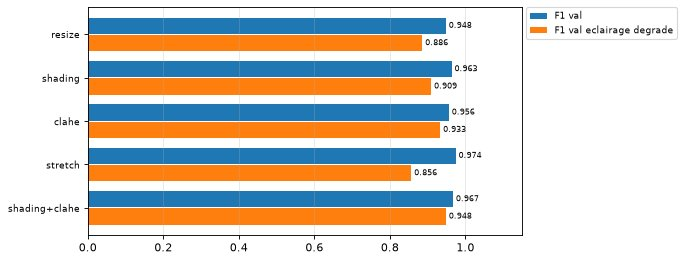

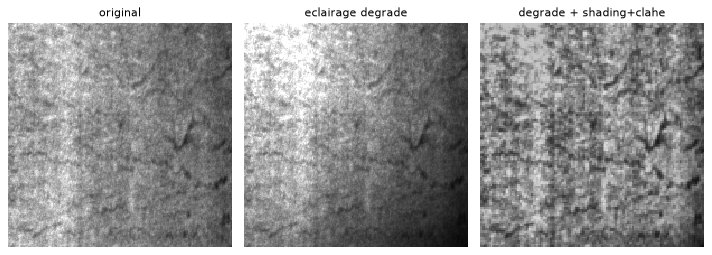

In [5]:
print("chaine retenue :", chosen, "->", PIPELINE)  # rappelle le choix et ses parametres
viz.compare_runs(probe, ["F1 val", "F1 val eclairage degrade"])  # barres : les deux F1 de chaque chaine
plt.show()  # affiche la figure maintenant
viz.compare(  # trois images cote a cote
    # l'originale, la meme sous eclairage degrade, puis la version degradee corrigee par la chaine retenue
    {"original": raw_val[0], "eclairage degrade": raw_val_dark[0], f"degrade + {chosen}": run_pipeline(raw_val_dark[0], PIPELINE)},
    size=3,  # taille de chaque image dans la figure
)

## Etapes 6 et 7 - Augmenter et charger par lots : donnees d'entrainement avec la chaine retenue

Le pretraitement est deterministe : on le calcule une fois par image et on garde le resultat en
memoire (uint8). L'augmentation, elle, est tiree a chaque epoque (retournements : les defauts
n'ont pas d'orientation privilegiee dans NEU-CLS ; sur une bande ou le sens de laminage compte,
une rotation de 90 degres serait interdite).

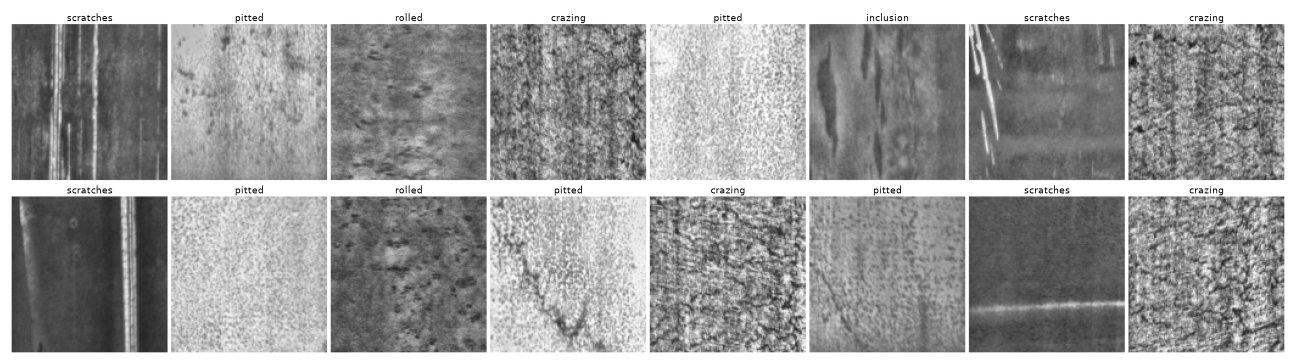

In [6]:
class PreprocessedDataset(Dataset):  # images pretraitees une fois pour toutes ; donne (tenseur normalise, classe) par numero
    def __init__(self, frame, pipeline, mean, std, augment=None):  # frame : tableau des images ; augment : transformations au hasard
        self.images = [run_pipeline(read_image(p), pipeline) for p in frame["path"]]  # lit et pretraite chaque image une seule fois
        self.targets = frame["label"].map(class_names.index).tolist()  # classe de chaque image, en numero
        self.mean, self.std, self.augment = mean, std, augment  # garde les reglages pour __getitem__

    def __len__(self):  # nombre d'images du jeu (le DataLoader en a besoin)
        return len(self.images)  # une entree par image

    def __getitem__(self, i):  # renvoie l'image numero i prete pour le reseau, et sa classe
        # (H, W, C) -> (C, H, W), conversion en tenseur de flottants, pixels ramenes dans [0, 1]
        x = torch.from_numpy(np.ascontiguousarray(self.images[i].transpose(2, 0, 1))).float() / peak_of(self.images[i])
        if self.augment is not None:  # entrainement seulement : augmentation tiree au hasard a chaque lecture
            x = self.augment(x)  # le reseau voit une variante de l'image (retournee ou non) : il generalise mieux
        # normalisation par canal (moyenne, ecart-type) et classe de l'image
        return (x - torch.tensor(self.mean).view(-1, 1, 1)) / torch.tensor(self.std).view(-1, 1, 1), self.targets[i]


def make_loaders(mean, std):  # construit les trois DataLoader (train, val, test) avec la normalisation donnee
    # augmentation : retournements horizontal et vertical, 1 fois sur 2
    flips = v2.Compose([v2.RandomHorizontalFlip(), v2.RandomVerticalFlip()])
    train = PreprocessedDataset(frames["train"], PIPELINE, mean, std, flips)  # jeu d'entrainement, avec augmentation
    gen = torch.Generator().manual_seed(SEED)  # generateur de hasard dedie : l'ordre des lots est reproductible
    return (  # renvoie un triplet de DataLoader (ils decoupent un jeu en lots de BATCH_SIZE images)
        # train : melange a chaque epoque (shuffle) ; drop_last : jette le dernier lot incomplet
        DataLoader(train, BATCH_SIZE, shuffle=True, drop_last=True, generator=gen),
        DataLoader(PreprocessedDataset(frames["val"], PIPELINE, mean, std), BATCH_SIZE),  # validation : sans augmentation ni melange
        DataLoader(PreprocessedDataset(frames["test"], PIPELINE, mean, std), BATCH_SIZE),  # test : idem
    )


train_loader, val_loader, test_loader = make_loaders(IMAGENET_MEAN, IMAGENET_STD)  # normalisation ImageNet : celle du resnet18 pre-entraine
images, targets = next(iter(train_loader))  # un lot d'entrainement : images (32, 3, 128, 128) et classes (32,)
# affiche 16 images du lot telles que le reseau les voit (mean / std servent a annuler la normalisation pour l'affichage)
viz.show_batch(images[:16], targets[:16].tolist(), class_names, mean=IMAGENET_MEAN, std=IMAGENET_STD, ncols=8)

## Etapes 8 a 10 - Modele, perte et optimiseur, entrainer : resnet18 pre-entraine, strategie partial

Tete neuve + `layer4` degele (taux x 0,1), BatchNorm des blocs geles en mode eval, AdamW,
taux divise par 2 quand la perte de validation stagne, meilleur modele selon la perte de
validation, arret anticipe. La courbe se met a jour pendant l'entrainement.

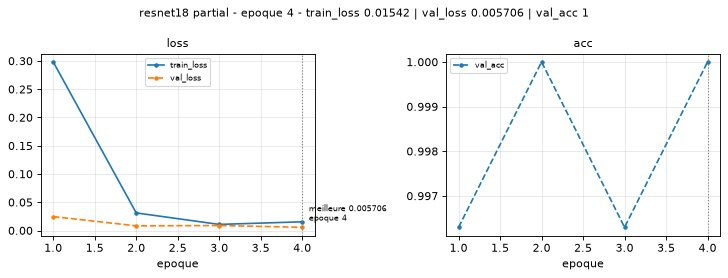

resnet18 : 62 s


In [7]:
def freeze_frozen_batchnorm(net):  # met en mode eval les BatchNorm dont les poids sont geles ; ne renvoie rien
    for module in net.modules():  # pour chaque couche du reseau (couches imbriquees comprises)
        # une couche BatchNorm (normalise ses entrees avec la moyenne et l'ecart-type du lot) dont aucun poids n'apprend
        if isinstance(module, nn.BatchNorm2d) and not any(p.requires_grad for p in module.parameters()):
            module.eval()  # elle garde ses statistiques ImageNet au lieu de les recalculer sur nos petits lots


@torch.no_grad()  # pas de gradient : on predit seulement
def predict_loader(net, loader, criterion=None):  # predit tout un DataLoader ; renvoie (probabilites, vraies classes, perte moyenne)
    net.eval()  # mode evaluation : dropout coupe, BatchNorm avec ses statistiques apprises
    probs, ys, total = [], [], 0.0  # probabilites et vraies classes de chaque lot ; somme des pertes
    for x, y in loader:  # pour chaque lot (images x, classes y)
        logits = net(x.to(DEVICE))  # logits : scores bruts du reseau, un par classe (avant softmax)
        if criterion is not None:  # si une fonction de perte est donnee
            total += criterion(logits, y.to(DEVICE)).item() * len(y)  # perte moyenne du lot x nombre d'images = perte totale du lot
        probs.append(torch.softmax(logits, 1).cpu())  # softmax : transforme les logits en probabilites positives de somme 1
        ys.append(y)  # garde les vraies classes du lot
    y = torch.cat(ys).numpy()  # toutes les vraies classes en un seul tableau numpy
    return torch.cat(probs).numpy(), y, total / len(y)  # probabilites (n, classes), classes (n,), perte moyenne par image


def fit(net, optimizer, criterion, epochs, title, checkpoint, freeze_bn=True):  # boucle d'entrainement ; renvoie (historique, duree en s)
    # divise le taux d'apprentissage par 2 quand la perte de validation ne baisse plus pendant 2 epoques
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)
    live = viz.LivePlot(metrics=("train_loss", "val_loss", "val_acc"), title=title)  # courbes mises a jour a chaque epoque
    best, bad, start = float("inf"), 0, time.time()  # meilleure perte de val (infinie au depart), epoques sans progres, chrono
    for epoch in range(1, epochs + 1):  # pour chaque epoque, numerotee a partir de 1
        net.train()  # mode entrainement : dropout actif, BatchNorm mises a jour
        if freeze_bn:  # reseau pre-entraine partiellement gele
            freeze_frozen_batchnorm(net)  # remet en mode eval les BatchNorm gelees (net.train() venait de les reactiver)
        total, seen = 0.0, 0  # somme des pertes et nombre d'images vues pendant l'epoque
        for x, y in train_loader:  # pour chaque lot d'entrainement
            x, y = x.to(DEVICE), y.to(DEVICE)  # envoie images et classes la ou se trouve le modele
            optimizer.zero_grad(set_to_none=True)  # efface les gradients du lot precedent (sinon ils s'additionnent)
            loss = criterion(net(x), y)  # passe avant : predictions du lot, puis perte (erreur) face aux vraies classes
            loss.backward()  # retropropagation : calcule le gradient de la perte pour chaque poids
            optimizer.step()  # l'optimiseur deplace chaque poids d'un petit pas dans le sens qui fait baisser la perte
            total, seen = total + loss.item() * len(y), seen + len(y)  # cumule la perte et le nombre d'images
        probs, y_true, val_loss = predict_loader(net, val_loader, criterion)  # fin d'epoque : mesure sur la validation
        scheduler.step(val_loss)  # le planificateur decide s'il baisse le taux d'apprentissage
        # ajoute un point aux courbes : perte train, perte val, exactitude val (part de predictions justes)
        live.update(epoch, train_loss=total / seen, val_loss=val_loss, val_acc=float((probs.argmax(1) == y_true).mean()))
        if val_loss < best:  # meilleure perte de validation jusqu'ici
            best, bad = val_loss, 0  # on la retient et on remet a 0 le compteur d'epoques sans progres
            torch.save(net.state_dict(), checkpoint)  # sauvegarde les poids de ce meilleur modele sur disque
        else:  # pas d'amelioration
            bad += 1  # une epoque de plus sans progres
            if bad >= PATIENCE:  # trop d'epoques sans progres
                break  # arret anticipe : le modele n'apprend plus rien d'utile (il risque de surapprendre)
    live.close()  # fige la figure finale
    # recharge les poids du meilleur modele (pas ceux de la derniere epoque) ; weights_only : ne charge que des tenseurs (plus sur)
    net.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
    return live.history, time.time() - start  # historique (une ligne par epoque) et duree totale en secondes


model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)  # resnet18 pre-entraine sur ImageNet
model.fc = nn.Linear(model.fc.in_features, len(class_names))  # tete neuve : 512 entrees -> un score par classe (6 ici)
for p in model.parameters():  # pour chaque tenseur de poids du reseau
    p.requires_grad = False  # gele : ce poids ne sera pas modifie par l'entrainement
for p in [*model.fc.parameters(), *model.layer4.parameters()]:  # poids de la tete et du dernier bloc (layer4)
    p.requires_grad = True  # degeles : seuls eux apprennent (strategie partial)
model.to(DEVICE)  # envoie le modele sur le processeur / la carte graphique
optimizer = torch.optim.AdamW(  # optimiseur AdamW : la regle qui corrige les poids a partir des gradients
    # deux groupes : la tete apprend au taux LR, layer4 a un taux 10 fois plus faible pour ne pas abimer le pre-entrainement
    [{"params": model.fc.parameters(), "lr": LR}, {"params": model.layer4.parameters(), "lr": LR * 0.1}],
    weight_decay=1e-4,  # tire doucement les poids vers 0 : limite le surapprentissage
)
# entrainement ; CrossEntropyLoss : perte classique de classification (forte quand la bonne classe a une probabilite faible)
history, seconds = fit(model, optimizer, nn.CrossEntropyLoss(), EPOCHS, "resnet18 partial", OUT / "resnet18_best.pt")
print(f"resnet18 : {seconds:.0f} s")  # duree d'entrainement

## Etapes 8 a 10 - Modele, perte et optimiseur, entrainer : en comparaison, un reseau ecrit de zero

Quatre blocs convolution -> BatchNorm -> ReLU -> MaxPool, moyenne spatiale, une couche de
classification (le CNN du cours, `simple_cnn` dans la toolbox). Sans poids pre-entraines, la
normalisation vient des statistiques du TRAIN (calculees apres pretraitement) et tout le reseau
apprend. Utile quand le domaine est trop loin d'ImageNet ou que la taille compte (390 000
parametres contre 11 millions).

normalisation du jeu : [0.511, 0.5111, 0.511] [0.1846, 0.1846, 0.1846]


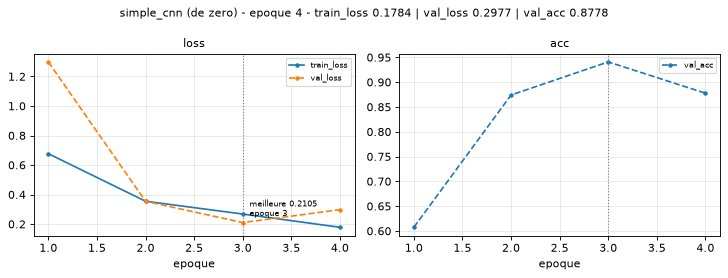

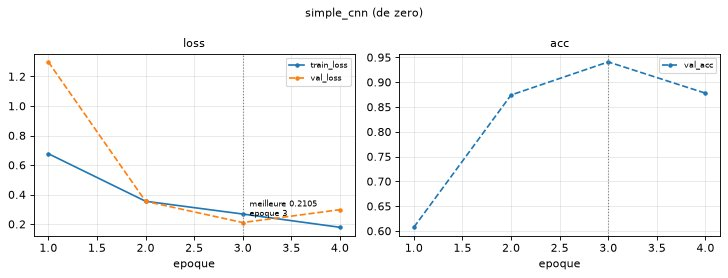

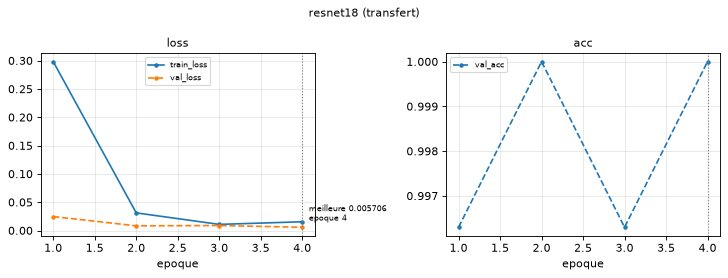

In [8]:
class ConvBlock(nn.Module):  # un bloc convolution -> BatchNorm -> ReLU -> MaxPool ; divise la taille de l'image par 2
    def __init__(self, cin, cout):  # cin : canaux en entree ; cout : canaux en sortie (nombre de filtres)
        super().__init__()  # initialise la partie nn.Module (obligatoire)
        self.block = nn.Sequential(  # couches appliquees l'une apres l'autre
            nn.Conv2d(cin, cout, 3, padding=1, bias=False),  # convolution 3x3 : cout filtres glissent sur l'image ; padding garde la taille
            nn.BatchNorm2d(cout),  # normalise chaque canal sur le lot : apprentissage plus stable (remplace le biais de la convolution)
            nn.ReLU(inplace=True),  # ReLU : garde les valeurs positives, met les negatives a 0 (non-linearite)
            nn.MaxPool2d(2),  # garde le maximum de chaque carre 2x2 : image deux fois plus petite
        )

    def forward(self, x):  # passe avant : ce que fait le bloc sur un lot x
        return self.block(x)  # applique les 4 couches


class SimpleCNN(nn.Module):  # petit reseau de convolution (CNN) ecrit de zero ; sort un score par classe
    def __init__(self, num_classes, channels=(32, 64, 128, 256), dropout=0.3, in_channels=3):  # channels : filtres de chaque bloc
        super().__init__()  # initialise nn.Module
        blocks, cin = [], in_channels  # liste des blocs ; cin = canaux en entree du prochain bloc (3 au depart)
        for cout in channels:  # pour chaque bloc a creer
            blocks.append(ConvBlock(cin, cout))  # bloc qui passe de cin a cout canaux
            cin = cout  # la sortie de ce bloc est l'entree du suivant
        self.features = nn.Sequential(*blocks)  # les 4 blocs enchaines : extraction des caracteristiques
        self.pool = nn.AdaptiveAvgPool2d(1)  # moyenne de chaque canal sur toute l'image : un nombre par canal, quelle que soit la taille
        # aplatit, dropout (eteint 30 % des valeurs au hasard pendant l'entrainement, contre le surapprentissage), puis un score par classe
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(cin, num_classes))

    def forward(self, x):  # passe avant : lot d'images -> logits
        return self.classifier(self.pool(self.features(x)))  # caracteristiques, moyenne spatiale, classification


stats_images = PreprocessedDataset(  # jeu temporaire : on ne garde que ses images pretraitees (.images)
    frames["train"].sample(n=min(500, len(frames["train"])), random_state=SEED),  # au plus 500 images du TRAIN, tirees au hasard
    PIPELINE,  # la chaine de pretraitement retenue
    [0, 0, 0],  # moyenne 0 et ...
    [1, 1, 1],  # ... ecart-type 1 : aucune normalisation (on veut justement la calculer)
).images  # .images : la liste des images pretraitees (uint8), sans passer par __getitem__
# tous les pixels a la suite, un par ligne (n, 3), ramenes dans [0, 1] comme dans le Dataset (/255 en 8 bits,
# /65535 en 16 bits : peak_of) ; float64 : sommes precises
pixels = np.concatenate([im.reshape(-1, 3).astype(np.float64) / peak_of(im) for im in stats_images])
DATA_MEAN, DATA_STD = pixels.mean(0).round(4).tolist(), pixels.std(0).round(4).tolist()  # moyenne et ecart-type par canal de NOS images
print("normalisation du jeu :", DATA_MEAN, DATA_STD)  # affiche ces statistiques
train_loader, val_loader, scratch_test_loader = make_loaders(DATA_MEAN, DATA_STD)  # DataLoader normalises avec ces statistiques
counts = frames["train"]["label"].value_counts().reindex(class_names).to_numpy()  # images d'entrainement par classe, ordre de class_names
# poids par classe = n / (classes x effectif) : une classe rare pese plus dans la perte, une classe frequente moins
class_weights = torch.tensor(len(frames["train"]) / (len(class_names) * counts), dtype=torch.float32).to(DEVICE)
scratch = SimpleCNN(len(class_names)).to(DEVICE)  # le petit CNN, poids tires au hasard
scratch_history, scratch_seconds = fit(  # entrainement complet du reseau de zero
    scratch,  # le reseau a entrainer
    torch.optim.AdamW(scratch.parameters(), lr=LR, weight_decay=1e-4),  # tous ses poids apprennent, au meme taux
    nn.CrossEntropyLoss(weight=class_weights),  # perte ponderee par classe
    SCRATCH_EPOCHS,  # nombre maximal d'epoques
    "simple_cnn (de zero)",  # titre de la courbe
    OUT / "simple_cnn_best.pt",  # fichier du meilleur modele
    freeze_bn=False,  # rien n'est gele : toutes les BatchNorm apprennent
)
train_loader, val_loader, test_loader = make_loaders(IMAGENET_MEAN, IMAGENET_STD)  # retour aux reglages du resnet18
viz.plot_history(history, best="val_loss:min", title="resnet18 (transfert)")  # courbes du resnet18 ; meilleure epoque marquee
viz.plot_history(scratch_history, best="val_loss:min", title="simple_cnn (de zero)")  # courbes du reseau de zero, pour comparer

## Etape 11 - Evaluer : sur le test (une seule fois)

- **F1 macro** : moyenne des F1 par classe, la metrique a suivre (une classe rare compte autant
  qu'une classe frequente) ; **balanced accuracy** : moyenne des rappels ;
- **log loss** : penalise les erreurs commises avec assurance ;
- matrice de confusion : quelles classes se confondent ;
- ROC et precision-rappel par classe (une contre toutes) ;
- calibration : une probabilite de 0,9 doit etre juste 9 fois sur 10 (sinon le seuil de rejet
  ne veut rien dire).

In [9]:
def summarize(probs, y):  # resume les performances d'un modele ; renvoie un dictionnaire de metriques
    pred = probs.argmax(1)  # classe predite = celle de plus forte probabilite
    return {  # nom de la metrique -> valeur
        "n_images": int(len(y)),  # nombre d'images evaluees
        "accuracy": float((pred == y).mean()),  # exactitude : part des images bien classees
        "balanced_accuracy": float(balanced_accuracy_score(y, pred)),  # moyenne des rappels par classe (insensible au desequilibre)
        "f1_macro": float(f1_score(y, pred, average="macro")),  # moyenne des F1 par classe : la metrique principale
        # log loss : penalise fort une erreur commise avec assurance ; labels : toutes les classes, meme absentes du test
        "log_loss": float(log_loss(y, probs, labels=list(range(len(class_names))))),
    }


test_probs, test_y, _ = predict_loader(model, test_loader)  # resnet18 : probabilites et vraies classes du test
scratch_probs, scratch_y, _ = predict_loader(scratch, scratch_test_loader)  # reseau de zero, avec SA normalisation
metrics = summarize(test_probs, test_y)  # metriques du resnet18
results = pd.DataFrame(  # tableau comparatif des deux modeles
    {  # une colonne par modele (transposee plus bas)
        # metriques du resnet18 + nombre de poids (numel = nombre d'elements d'un tenseur) + duree d'entrainement
        "resnet18 partial": {**metrics, "parametres": sum(p.numel() for p in model.parameters()), "temps (s)": round(seconds)},
        "simple_cnn (de zero)": {  # memes informations pour le reseau de zero
            **summarize(scratch_probs, scratch_y),  # ses metriques
            "parametres": sum(p.numel() for p in scratch.parameters()),  # son nombre total de poids
            "temps (s)": round(scratch_seconds),  # sa duree d'entrainement
        },
    }
).T  # .T transpose le tableau : une ligne par modele
display(results)  # affiche le tableau

,n_images,accuracy,balanced_accuracy,f1_macro,log_loss,parametres,temps (s)
resnet18 partial,270.0,1.000000,1.000000,1.000000,0.005929,11179590.0,62.0
simple_cnn (de zero),270.0,0.948148,0.948148,0.948715,0.190595,390438.0,95.0


In [10]:
test_pred = test_probs.argmax(1)  # classes predites par le resnet18 sur le test
# par classe : precision (parmi les images predites de cette classe, part de justes), rappel (parmi les vraies, part retrouvee), F1
viz.classification_report(test_y, test_pred, class_names)

,precision,recall,f1,support
crazing,1.0,1.0,1.0,45
inclusion,1.0,1.0,1.0,45
patches,1.0,1.0,1.0,45
pitted,1.0,1.0,1.0,45
rolled,1.0,1.0,1.0,45
scratches,1.0,1.0,1.0,45
accuracy,NaN,NaN,1.0,270
macro avg,1.0,1.0,1.0,270
weighted avg,1.0,1.0,1.0,270


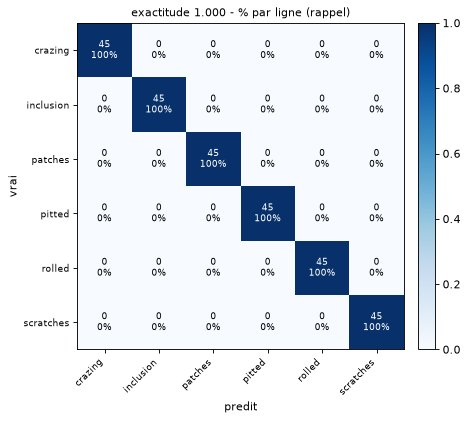

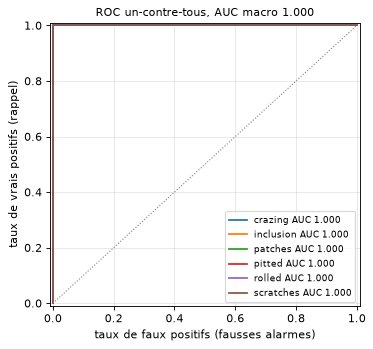

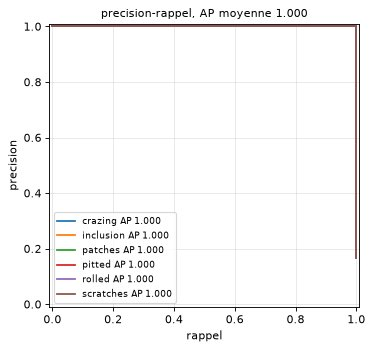

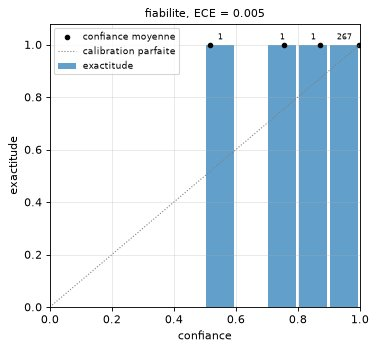

In [11]:
viz.confusion_matrix(test_y, test_pred, class_names)  # matrice de confusion : ligne = vraie classe, colonne = classe predite
viz.roc_curves(test_y, test_probs, class_names)  # courbes ROC, une classe contre toutes ; AUC = aire sous la courbe (1 = parfait)
viz.pr_curves(test_y, test_probs, class_names)  # courbes precision-rappel par classe, quand on fait varier le seuil
viz.calibration(test_y, test_probs)  # calibration : la confiance annoncee correspond-elle a l'exactitude reelle ?
plt.show()  # plusieurs figures dans la cellule : affichees dans l'ordre

Les erreurs les plus sures d'elles d'abord : une erreur a 0,95 vient souvent d'une etiquette
fausse ou d'un cas ambigu, a regarder AVANT de toucher au modele.

resnet18 : 0 erreur(s) sur 270
simple_cnn : 14 erreur(s) sur 270


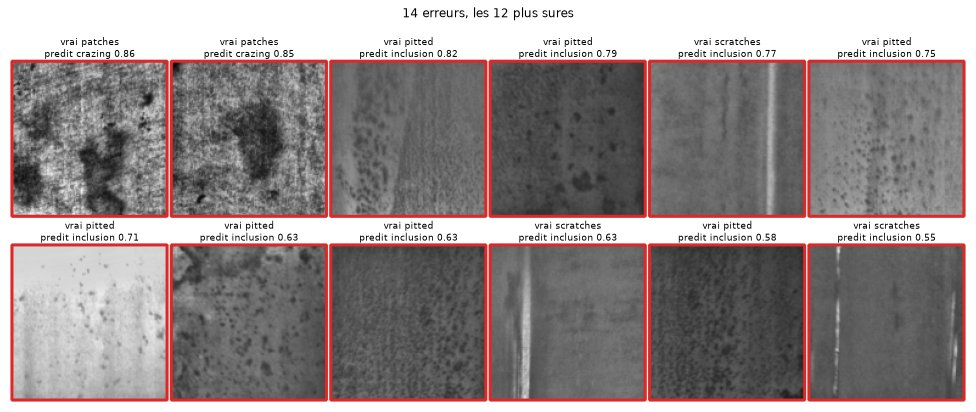

In [12]:
test_images = [run_pipeline(read_image(p), PIPELINE) for p in frames["test"]["path"]]  # images de test pretraitees (pour l'affichage)
for name, probs, y in (("resnet18", test_probs, test_y), ("simple_cnn", scratch_probs, scratch_y)):  # pour chacun des deux modeles
    wrong = int((probs.argmax(1) != y).sum())  # nombre d'images mal classees
    print(f"{name} : {wrong} erreur(s) sur {len(y)}")  # bilan des erreurs
if (scratch_probs.argmax(1) != scratch_y).any():  # si le reseau de zero a fait au moins une erreur
    viz.errors_gallery(test_images, scratch_y, scratch_probs.argmax(1), scratch_probs, class_names, k=12)  # ses 12 erreurs les plus sures
if (test_probs.argmax(1) != test_y).any():  # si le resnet18 a fait au moins une erreur
    viz.errors_gallery(test_images, test_y, test_pred, test_probs, class_names, k=12)  # idem pour le resnet18

## Etape 11 - Evaluer : Grad-CAM, ecrit a la main (ou le modele a-t-il regarde ?)

Deux crochets sur la derniere couche de convolution (`layer4`) : on garde ses activations et leur
gradient par rapport au score de la classe predite ; chaque carte d'activation est ponderee par
la moyenne de son gradient ; on garde la partie positive, agrandie a la taille de l'image. Une
zone chaude hors du defaut (bord, coin, inscription) signale un raccourci : le modele ne
generalisera pas.

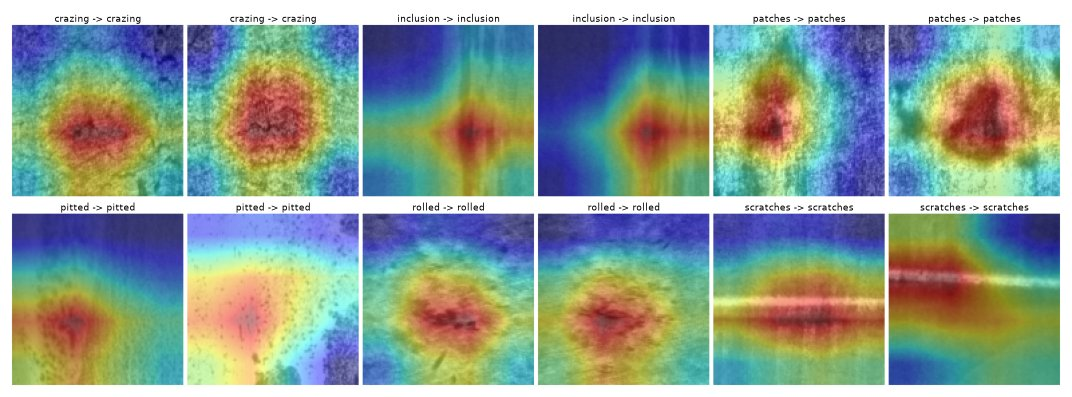

In [13]:
class GradCAM:  # Grad-CAM : carte de chaleur des zones de l'image qui ont fait pencher la decision
    def __init__(self, net, layer):  # net : le modele ; layer : la couche observee (la derniere convolution)
        self.net, self.store = net.eval(), {}  # modele en mode evaluation ; store garde activations et gradients
        self.handle = layer.register_forward_hook(self.keep)  # crochet (hook) : self.keep sera appelee a chaque passage dans la couche

    def keep(self, module, inputs, output):  # appelee par PyTorch juste apres la couche ; output = ses activations (sorties)
        self.store["activations"] = output  # garde les activations : (lot, canaux, h, w)
        output.register_hook(lambda grad: self.store.__setitem__("gradients", grad))  # 2e crochet : garde leur gradient au backward

    def __call__(self, tensor):  # carte pour UNE image ; renvoie (carte (H, W) dans [0, 1], classe predite)
        # ajoute l'axe du lot (1 image) ; requires_grad : le gradient doit traverser le backbone gele
        x = tensor.unsqueeze(0).to(DEVICE).requires_grad_(True)
        logits = self.net(x)  # passe avant (le crochet enregistre les activations)
        index = int(logits.argmax(1))  # classe predite
        self.net.zero_grad(set_to_none=True)  # efface d'eventuels anciens gradients
        logits[0, index].backward()  # le score de LA classe, pas la perte ; le 2e crochet enregistre le gradient
        weights = self.store["gradients"].mean(dim=(2, 3), keepdim=True)  # importance de chaque canal = moyenne de son gradient
        cam = F.relu((weights * self.store["activations"]).sum(dim=1, keepdim=True))  # somme ponderee des cartes ; ReLU garde le positif
        # agrandit la carte (4x4 ici) a la taille de l'image ; [0, 0] : premiere image, premier canal ; detach : sans gradient
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].detach().cpu()
        # carte ramenee dans [0, 1] pour l'affichage (1e-8 evite une division par 0), et classe predite
        return ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).numpy(), index

    def close(self):  # retire le crochet quand on a fini
        self.handle.remove()  # sinon il resterait actif sur le modele


cam = GradCAM(model, model.layer4)  # Grad-CAM sur le dernier bloc de convolution du resnet18
picked = frames["test"].groupby("label").head(2).index  # 2 images de test par classe (leurs numeros de ligne)
overlays, titles = [], []  # images avec la carte superposee, et leurs titres
for i in picked:  # pour chaque image choisie
    heat, index = cam(test_loader.dataset[i][0])  # carte de chaleur et classe predite ([0] : le tenseur, sans la classe)
    overlays.append(viz.overlay_heatmap(test_images[i], heat, alpha=0.45))  # superpose la carte (opacite 45 %) a l'image pretraitee
    titles.append(f"{frames['test']['label'][i]} -> {class_names[index]}")  # titre : vraie classe -> classe predite
cam.close()  # retire le crochet du modele
viz.grid(overlays, titles, ncols=6, size=2.2)  # planche de 6 colonnes

## Etape 11 - Evaluer : seuil de rejet, choisi sur la validation

En production, une image dont la probabilite maximale est basse part vers un operateur au lieu
d'etre classee. On cherche, sur la VALIDATION, le plus petit seuil qui garantit une exactitude
d'au moins `TARGET_ACCEPTED_ACCURACY` sur les images acceptees ; le test dit ensuite ce que ce
seuil donne sur des images jamais vues (taux de rejet, exactitude des acceptees).

seuil de rejet (validation) : 0.654
test : 0.4% rejetees, exactitude des acceptees 100.00%


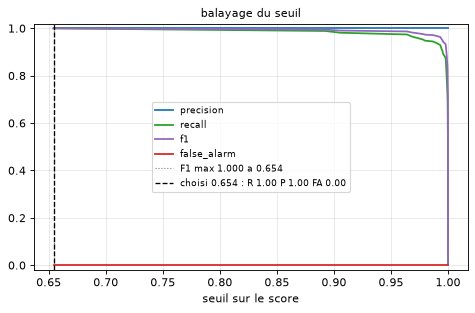

In [14]:
val_probs, val_y, _ = predict_loader(model, val_loader)  # probabilites du resnet18 sur la VALIDATION
confidence, correct = val_probs.max(1), val_probs.argmax(1) == val_y  # confiance = probabilite maximale ; correct = prediction juste
order = np.argsort(-confidence)  # numeros des images, de la plus sure a la moins sure
# pour chaque k : exactitude obtenue si on accepte seulement les k images les plus sures
accepted_accuracy = np.cumsum(correct[order]) / np.arange(1, len(order) + 1)
ok = np.where(accepted_accuracy >= TARGET_ACCEPTED_ACCURACY)[0]  # les k qui atteignent l'exactitude visee
# seuil = confiance de la derniere image acceptee pour le plus grand k valable ; aucun k valable : seuil 1.0 (tout est rejete)
REJECT_BELOW = float(confidence[order][ok.max()]) if len(ok) else 1.0
fig, sweep = viz.threshold_sweep(correct.astype(int), confidence, chosen=REJECT_BELOW)  # courbes selon le seuil, seuil choisi marque
test_conf = test_probs.max(1)  # confiance du modele sur chaque image de test
accepted = test_conf >= REJECT_BELOW  # vrai si l'image est acceptee (classee automatiquement)
print(f"seuil de rejet (validation) : {REJECT_BELOW:.3f}")  # le seuil retenu
# au test : part des images rejetees et exactitude sur les images acceptees
print(f"test : {1 - accepted.mean():.1%} rejetees, exactitude des acceptees {(test_pred[accepted] == test_y[accepted]).mean():.2%}")

## Etape 12 - Sauvegarder et exporter : export ONNX verifie et carte du modele

Le pretraitement reste hors du graphe (OpenCV, decrit dans la carte) ; la normalisation aussi
(decrite par `mean` / `std`). Verification sur 3 vraies images avec un lot different de celui de
l'export ; latence mesuree avec onnxruntime.

In [15]:
model_cpu = model.cpu().eval()  # modele sur CPU, en mode evaluation (attention : c'est le meme objet, model passe aussi sur CPU)
torch.onnx.export(  # export ONNX : un fichier standard que onnxruntime, C# ou C++ savent executer sans PyTorch
    model_cpu,  # le modele a exporter
    (torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE),),  # exemple d'entree (tuple d'arguments) : un lot de 2 images noires, fixe la forme
    str(EXPORT / "model.onnx"),  # fichier de sortie
    input_names=["input"],  # nom de l'entree dans le fichier ONNX
    output_names=["logits"],  # nom de la sortie
    dynamic_shapes={"x": {0: torch.export.Dim("batch", min=1, max=1024)}},  # x : nom de l'argument de forward ; lot dynamique
    opset_version=18,  # version du jeu d'operations ONNX
    dynamo=True,  # l'exporteur torch.export (le defaut depuis PyTorch 2.9)
    external_data=False,  # poids dans le meme fichier .onnx
)
session = ort.InferenceSession(str(EXPORT / "model.onnx"), providers=["CPUExecutionProvider"])  # charge le modele ONNX, execution sur CPU
real = torch.stack([val_loader.dataset[i][0] for i in range(3)])  # lot de 3 vraies images de validation (taille de lot differente)
with torch.no_grad():  # sans gradient
    reference = model_cpu(real).numpy()  # sortie de PyTorch : la reference
onnx_out = session.run(None, {"input": real.numpy()})[0]  # sortie ONNX des memes images (None = toutes les sorties ; [0] = la premiere)
diff, scale = float(np.abs(reference - onnx_out).max()), float(np.abs(reference).max())  # plus grand ecart, ordre de grandeur des sorties
assert diff <= 1e-4 + 1e-3 * scale, f"ONNX different de PyTorch : {diff:.2e}"  # arrete tout si l'ecart depasse la tolerance
one = real[:1].numpy()  # une seule image, pour mesurer la latence (temps de reponse)
for _ in range(3):  # 3 passages d'echauffement, non chronometres
    session.run(None, {"input": one})  # les premiers appels sont toujours plus lents
start = time.perf_counter()  # chrono precis
for _ in range(20):  # 20 predictions chronometrees
    session.run(None, {"input": one})  # prediction d'une image
latency = round(1000 * (time.perf_counter() - start) / 20, 2)  # latence moyenne en millisecondes par image
print(f"verification ONNX OK (ecart {diff:.1e}) | onnxruntime CPU {latency} ms / image")  # bilan de la verification

card = {  # carte du modele : tout ce que la production doit savoir pour utiliser model.onnx
    "task": "classification",  # type de tache
    "model_name": "resnet18",  # architecture
    "created_utc": datetime.now(UTC).strftime("%Y-%m-%dT%H:%M:%SZ"),  # date et heure de creation (heure universelle)
    "framework": {"python": platform.python_version(), "torch": torch.__version__, "onnxruntime": ort.__version__},  # versions utilisees
    "input": {  # description de l'entree du reseau
        "name": "input",  # nom de l'entree ONNX
        "layout": "NCHW",  # ordre des axes : lot (N), canaux (C), hauteur (H), largeur (W)
        "height": IMAGE_SIZE,  # hauteur attendue
        "width": IMAGE_SIZE,  # largeur attendue
        "channels": 3,  # nombre de canaux
        "color": "RGB",  # ordre des canaux
        "dtype": "float32",  # type des nombres
        "scale": "divide by 255 (8 bits) or 65535 (16 bits)",  # mise a l'echelle des pixels dans [0, 1]
        "mean": IMAGENET_MEAN,  # moyenne de normalisation
        "std": IMAGENET_STD,  # ecart-type de normalisation
        "resize": "stretch",  # redimensionnement sans garder les proportions (deja fait par le pretraitement)
        "letterbox_pad_value": None,  # pas de letterbox (image redimensionnee sans deformation puis bordee) en classification
        "dynamic_batch": True,  # le lot peut avoir n'importe quelle taille
        "read_color": READ_COLOR,  # couleur de lecture du fichier, avant le pretraitement
    },
    "preprocess": PIPELINE,  # chaine de pretraitement a rejouer, avec tous ses parametres
    "outputs": [  # description des sorties
        {  # une seule sortie
            "name": "logits",  # son nom
            "shape": ["batch", len(class_names)],  # sa forme : (lot, nombre de classes)
            "description": "scores avant softmax ; classe = argmax, probabilites = softmax",  # comment l'interpreter
        }
    ],
    "class_names": class_names,  # noms des classes, dans l'ordre des sorties
    "thresholds": {"reject_below_probability": REJECT_BELOW},  # seuil de rejet choisi sur la validation
    "postprocess": {"reject": "probabilite max < thresholds.reject_below_probability -> revue par un operateur"},  # regle de rejet
    "metrics": {k: metrics[k] for k in ("accuracy", "balanced_accuracy", "f1_macro", "n_images")},  # metriques du test
    "latency_ms": {"onnxruntime_cpu_ms": latency},  # latence mesuree
    "files": {"onnx": "model.onnx"},  # nom du fichier du modele
    "notes": f"notebook 07 ; pretraitement choisi a la metrique : {chosen} ; verification ONNX ecart {diff:.2e}",  # notes libres
}
(EXPORT / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")  # ecrit la carte en JSON lisible (indentation 2)
print(json.dumps(card["preprocess"]))  # affiche la chaine de pretraitement retenue

[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


verification ONNX OK (ecart 5.7e-06) | onnxruntime CPU 7.0 ms / image
[{"name": "shading_division", "sigma": 40.0, "method": "gaussian", "downscale": 4, "keep_mean": true}, {"name": "clahe", "clip_limit": 2.0, "tile_grid": 8}, {"name": "resize", "size": 128, "interpolation": "auto"}]


## Etape 13 - Predire : sans PyTorch

La carte suffit : on rejoue sa chaine `preprocess` (par nom), puis mise a l'echelle,
normalisation, onnxruntime, softmax, rejet. C'est le programme de production, en 20 lignes.

ecart max avec PyTorch : 6.3e-07


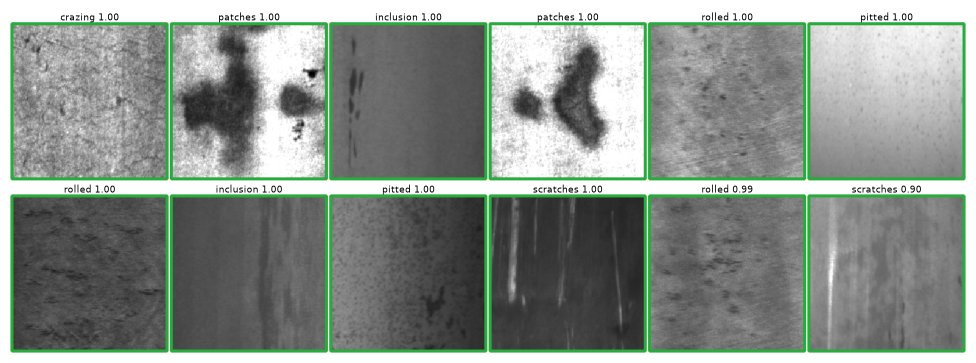

In [16]:
card = json.loads((EXPORT / "model_card.json").read_text(encoding="utf-8"))  # relit la carte sur disque, comme le ferait la production


def predict_file(path):  # predit un fichier avec ONNX et numpy seulement ; renvoie (classe ou "a_revoir", probabilites)
    spec = card["input"]  # description de l'entree
    image = read_image(path, spec["read_color"])  # lecture dans la couleur indiquee par la carte
    for step in card["preprocess"]:  # pour chaque etape de pretraitement de la carte
        image = OPS[step["name"]](image, **{k: v for k, v in step.items() if k != "name"})  # rejoue l'operation par son nom
    x = image.astype(np.float32) / peak_of(image)  # pixels ramenes dans [0, 1]
    # normalisation avec la moyenne / l'ecart-type de la carte
    x = (x - np.array(spec["mean"], np.float32)) / np.array(spec["std"], np.float32)
    # (H, W, C) -> (C, H, W), [None] ajoute l'axe du lot ; execution ONNX ; [0][0] : 1re sortie, 1re image ; float64 : calcul precis
    logits = session.run(None, {spec["name"]: np.ascontiguousarray(x.transpose(2, 0, 1)[None])})[0][0].astype(np.float64)
    probs = np.exp(logits - logits.max())  # softmax ecrit a la main : exponentielle (moins le max, pour eviter un debordement)...
    probs /= probs.sum()  # ... puis division par la somme : probabilites de somme 1
    # classe la plus probable si sa probabilite atteint le seuil de rejet ; sinon "a_revoir" (l'image part chez un operateur)
    label = card["class_names"][int(probs.argmax())] if probs.max() >= card["thresholds"]["reject_below_probability"] else "a_revoir"
    return label, probs  # decision et probabilites


sample = frames["test"].sample(12, random_state=SEED)  # 12 images de test tirees au hasard
predictions = [predict_file(p) for p in sample["path"]]  # prediction sans PyTorch pour chacune
# plus grand ecart entre ces probabilites et celles de PyTorch pour les memes images (meme numero de ligne)
gap = np.abs(np.stack([p for _, p in predictions]) - test_probs[sample.index.to_numpy()]).max()
print(f"ecart max avec PyTorch : {gap:.1e}")  # doit etre minuscule
viz.grid(  # planche des 12 images avec leur decision
    [read_image(p) for p in sample["path"]],  # les images d'origine
    [f"{lab} {pr.max():.2f}" for lab, pr in predictions],  # titre : decision et probabilite maximale
    ncols=6,  # 6 colonnes
    borders=[lab == t for (lab, _), t in zip(predictions, sample["label"])],  # cadre vert si la decision est juste, rouge sinon
)

## Resultats

En mode QUICK (4 epoques), le resnet18 atteint deja 99 a 100 % au test et le reseau de zero reste
nettement en dessous : le pre-entrainement vaut de l'or quand les donnees sont rares. La recette
(`resnet18_partial`, 10 epoques) atteint 100 % ; `simple_cnn` (15 epoques) 97 %.

In [17]:
# tableau final : metriques du test des deux modeles, cote a cote
viz.metrics_table({"resnet18 partial (test)": metrics, "simple_cnn (test)": summarize(scratch_probs, scratch_y)})

,n_images,accuracy,balanced_accuracy,f1_macro,log_loss
resnet18 partial (test),270.0,1.000,1.000,1.000,0.006
simple_cnn (test),270.0,0.948,0.948,0.949,0.191


## Passer en production

```yaml
# recipes/classification/configs/resnet18_partial.yaml, avec la chaine retenue ici
data: {root: data/raw/neu_cls_flat, layout: class_folders, color: rgb}
split: {file: outputs/classification/split.csv, strategy: stratified, val_fraction: 0.15, test_fraction: 0.15}
preprocess:            # recopier PIPELINE (affiche a l'etape 5)
  - {name: resize, size: 128}
augment: [{name: hflip}, {name: vflip}]
model: {name: resnet18, pretrained: true, transfer: {strategy: partial, unfreeze_last: 1, backbone_lr_factor: 0.1}}
train: {epochs: 10, batch_size: 32, lr: 0.001, weight_decay: 0.0001, patience: 4, scheduler: plateau}
export: {openvino: true}
```

```
python recipes/preprocessing/scripts/compare.py --config recipes/preprocessing/configs/<...>.yaml   # le choix a la metrique
python recipes/classification/scripts/run.py --config recipes/classification/configs/resnet18_partial.yaml
python -m vtb.serve --model outputs/notebooks/07_classification/export
python tools/make_golden.py --model outputs/notebooks/07_classification/export --images data/raw/neu_cls_flat/crazing
```

Controle : (a) la chaine de la carte, rejouee par `vtb.preprocess.Pipeline`, donne exactement
les memes pixels que les fonctions du notebook ; (b) le predicteur de production rend les memes
classes et probabilites ; (c) le decoupage est celui de la recette.

In [18]:
from vtb.preprocess import Pipeline  # Pipeline : la chaine de pretraitement de la toolbox (celle de la production)
from vtb.serve.predictor import OnnxPredictor  # OnnxPredictor : le predicteur de production (ONNX + carte, sans PyTorch)

pipeline = Pipeline(card["preprocess"])  # construit la chaine de la toolbox a partir de la carte
pixel_gap = max(  # plus grand ecart de pixel entre la toolbox et le notebook, sur les 12 images
    # pour chaque image : ecart maximal entre les deux chaines (converties en entiers pour pouvoir soustraire sans debordement)
    int(np.abs(pipeline(read_image(p)).astype(int) - run_pipeline(read_image(p), PIPELINE).astype(int)).max())
    for p in sample["path"]  # pour chacune des 12 images de l'echantillon
)
print("ecart de pixels Pipeline vtb / notebook :", pixel_gap)  # 0 attendu : memes pixels
predictor = OnnxPredictor(EXPORT)  # charge model.onnx et la carte du dossier d'export
gaps = []  # plus grand ecart de probabilite pour chaque image
for path, (_, probs) in zip(sample["path"], predictions):  # pour chaque image et les probabilites calculees par le notebook
    out = predictor(read_image(path, predictor.color))  # prediction de production (lecture dans la couleur de la carte)
    assert out["label"] == card["class_names"][int(probs.argmax())]  # meme classe que le notebook, sinon arret
    gaps.append(max(abs(out["probabilities"][n] - float(p)) for n, p in zip(class_names, probs)))  # plus grand ecart sur les classes
print(f"OnnxPredictor : memes classes, ecart max des probabilites {max(gaps):.1e}")  # bilan de la comparaison
recipe_split = Path("outputs/classification/split.csv")  # decoupage ecrit par la recette (s'il existe)
if recipe_split.exists():  # seulement si la recette a deja tourne
    # sous-ensemble de chaque image selon la recette ; keep_default_na=False : aucun texte n'est pris pour une valeur manquante
    theirs = pd.read_csv(recipe_split, keep_default_na=False).set_index("path")["split"]
    print(  # part des images rangees dans le meme sous-ensemble par le notebook et par la recette
        # compare image par image (reindex aligne la recette sur l'ordre du catalogue)
        f"decoupage identique a la recette : {(catalog.set_index('path')['split'] == theirs.reindex(catalog['path']).to_numpy()).mean():.1%}"
    )

ecart de pixels Pipeline vtb / notebook : 0
OnnxPredictor : memes classes, ecart max des probabilites 4.9e-07


decoupage identique a la recette : 100.0%


## Adapter a tes donnees

1. `DATA_DIR` : un sous-dossier par classe (`DATA_DIR/<classe>/<image>`) ; images 8 ou 16 bits,
   grises ou couleur. Autres rangements (CSV, dossiers train/val/test) : notebook 01, section 3.
2. Plusieurs images par piece / bobine ? Remplacer le decoupage des etapes 3 et 4 par le
   decoupage groupe du notebook 01 (sinon le test est optimiste).
3. `CANDIDATES` : ajouter les chaines qui ont un sens pour ton eclairage (notebook 02 pour les
   operations) ; la sonde lineaire choisit.
4. `IMAGE_SIZE` : le plus petit defaut doit rester visible (quelques pixels au moins).
5. `QUICK = False` pour les reglages de la recette ; `TARGET_ACCEPTED_ACCURACY` selon le cout d'une
   erreur face au cout d'une revue.